In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hcipy as hci

In [2]:
pupil_grid = hci.make_pupil_grid(128, 1.0)
x = pupil_grid.x
y = pupil_grid.y

In [3]:
amp_sym = 0.01
w = 0.02
sym = amp_sym*np.exp(-(x/w)**2)
# sym = amp_sym*np.cos(2*np.pi*250*x)
sym_field = hci.Field(np.exp(1j*sym), pupil_grid)

In [4]:
amp_asym = 0.01
# asym = amp_asym*np.sin(2*np.pi*25*x)
asym = amp_asym*np.sin(2*np.pi*1.0*x)
# asym = amp_asym*x
asym_field = hci.Field(np.exp(1j*asym), pupil_grid)

In [5]:
sum_field = hci.Field(np.exp(1j*(sym+asym)), pupil_grid)

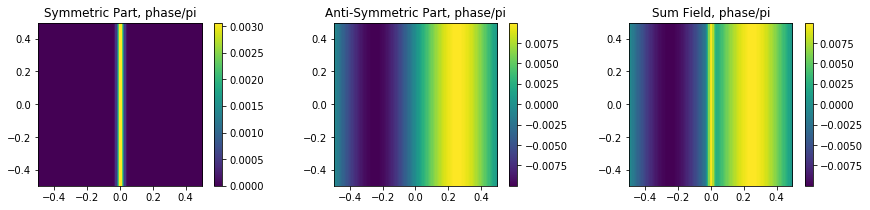

In [6]:
plt.figure(figsize=(15, 3))
plt.subplot(1,3,1)
plt.title('Symmetric Part, phase/pi')
hci.imshow_field(np.angle(sym_field)/np.pi)
plt.colorbar()
plt.subplot(1,3,2)
plt.title('Anti-Symmetric Part, phase/pi')
hci.imshow_field(np.angle(asym_field))
plt.colorbar()
plt.subplot(1,3,3)
plt.title('Sum Field, phase/pi')
hci.imshow_field(np.angle(sum_field))
plt.colorbar()

In [7]:
ft = hci.fourier.make_fourier_transform(pupil_grid, q=1)

In [8]:
foc_sym_field = ft.forward(sym_field)
foc_asym_field = ft.forward(asym_field)
foc_sum_field = ft.forward(sum_field)

In [9]:
sq_w = int(np.sqrt(len(foc_sym_field)))

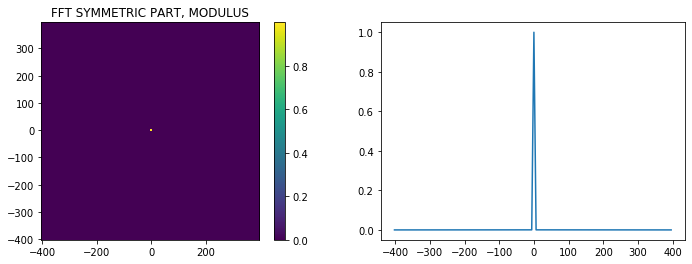

In [10]:
plt.figure(figsize=(12,4))
plt.subplot(121)
plt.title('FFT SYMMETRIC PART, MODULUS')
hci.imshow_field(np.absolute(foc_sym_field))
plt.colorbar()
plt.subplot(122)
plt.plot(foc_sym_field.grid.x.reshape(sq_w, sq_w)[sq_w//2,:]
         , np.absolute(foc_sym_field.reshape(sq_w, sq_w)[sq_w//2,:]))

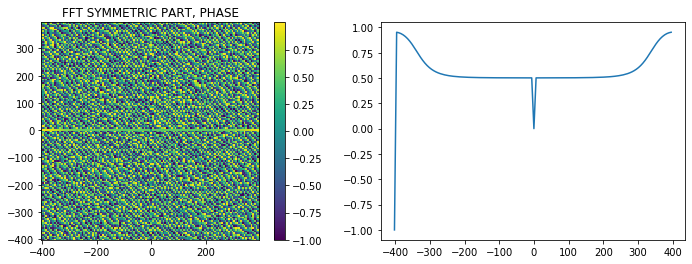

In [11]:
plt.figure(figsize=(12,4))
plt.subplot(121)
plt.title('FFT SYMMETRIC PART, PHASE')
hci.imshow_field(np.angle(foc_sym_field)/np.pi)
plt.colorbar()
plt.subplot(122)
plt.plot(foc_sym_field.grid.x.reshape(sq_w, sq_w)[sq_w//2,:]
         , np.angle(foc_sym_field.reshape(sq_w, sq_w)[sq_w//2,:])/np.pi)

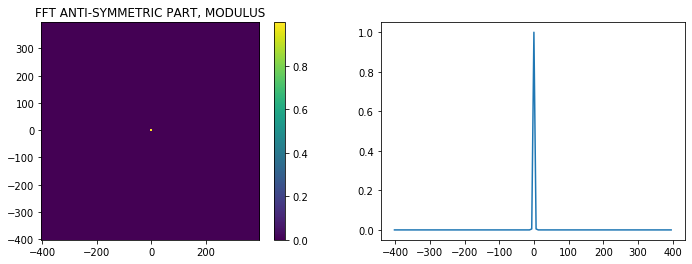

In [12]:
plt.figure(figsize=(12,4))
plt.subplot(121)
plt.title('FFT ANTI-SYMMETRIC PART, MODULUS')
hci.imshow_field(np.absolute(foc_asym_field))
plt.colorbar()
plt.subplot(122)
plt.plot(foc_sym_field.grid.x.reshape(sq_w, sq_w)[sq_w//2,:]
         , np.absolute(foc_asym_field.reshape(sq_w, sq_w)[sq_w//2,:]))

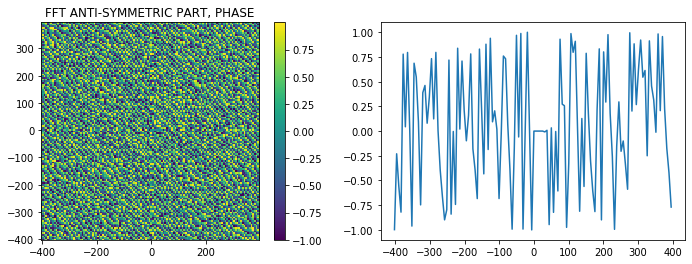

In [13]:
plt.figure(figsize=(12,4))
plt.subplot(121)
plt.title('FFT ANTI-SYMMETRIC PART, PHASE')
hci.imshow_field(np.angle(foc_asym_field)/np.pi)
plt.colorbar()
plt.subplot(122)
plt.plot(foc_sym_field.grid.x.reshape(sq_w, sq_w)[sq_w//2,:]
         , np.angle(foc_asym_field.reshape(sq_w, sq_w)[sq_w//2,:])/np.pi)

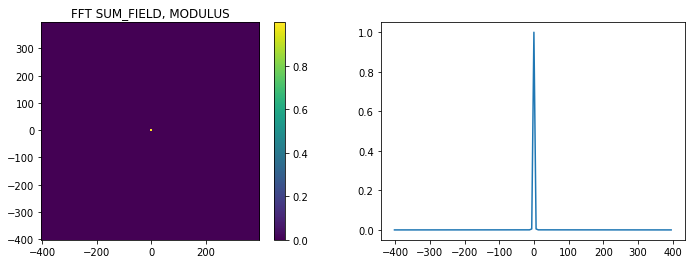

In [14]:
plt.figure(figsize=(12,4))
plt.subplot(121)
plt.title('FFT SUM_FIELD, MODULUS')
hci.imshow_field(np.absolute(foc_sum_field))
plt.colorbar()
plt.subplot(122)
plt.plot(foc_sym_field.grid.x.reshape(sq_w, sq_w)[sq_w//2,:]
         , np.absolute(foc_sum_field.reshape(sq_w, sq_w)[sq_w//2,:]))

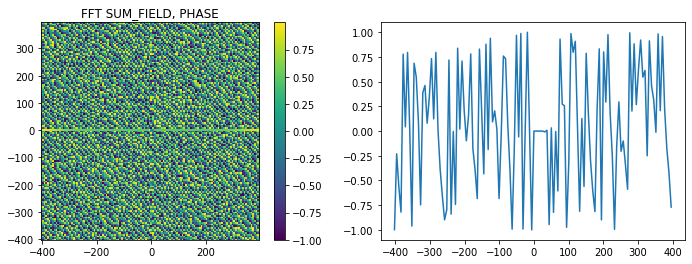

In [15]:
plt.figure(figsize=(12,4))
plt.subplot(121)
plt.title('FFT SUM_FIELD, PHASE')
hci.imshow_field(np.angle(foc_sum_field)/np.pi)
plt.colorbar()
plt.subplot(122)
plt.plot(foc_sum_field.grid.x.reshape(sq_w, sq_w)[sq_w//2,:]
         , np.angle(foc_asym_field.reshape(sq_w, sq_w)[sq_w//2,:])/np.pi)